In [1]:
import numpy as np

from challenge.dataset import Dataset
from challenge.models import FeatureBuilder, FeatureConfig
import matplotlib.pyplot as plt
from challenge.visuals import *

In [2]:
seed = 42

rng = np.random.default_rng(seed)

cfg = FeatureConfig(
    min_area_rel=0.0001,  # permissive
    min_edge_density=0.0,  # irrelevant now
    use_mser=True,
    mser_min_area_rel=0.0008,  # best efficiency
    mser_max_area_rel=0.25,  # best recall
    dedup_iou_thresh=0.40,  # good trade-off
)

In [3]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")

In [4]:
idx = rng.integers(low=0, high=len(train_data), size=500)
tiny_train = [train_data[i] for i in idx]
idx = rng.integers(low=0, high=len(val_data), size=100)
tiny_val = [val_data[i] for i in idx]

In [5]:
model = FeatureBuilder(cfg)

In [6]:
X_train, y_train = model.build_training_set(tiny_train)
X_val, y_val = model.build_training_set(tiny_val)

  0%|          | 0/500 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:10<00:00,  9.28it/s]


In [7]:
val_boxes = model.propose_boxes(tiny_val)

In [8]:
# np.save("../data/processed/X_train.npy", X_train)
# np.save("../data/processed/y_train.npy", y_train)
# np.save("../data/processed/train_img_ids.npy", train_img_ids)
# np.save("../data/processed/X_val.npy", X_val)
# np.save("../data/processed/y_val.npy", y_val)
# np.save("../data/processed/val_img_ids.npy", val_img_ids)


In [9]:
# X_train, y_train = (
#     np.load("../data/processed/X_train.npy"),
#     np.load("../data/processed/y_train.npy"),
# )
# X_val, y_val = (
#     np.load("../data/processed/X_val.npy"),
#     np.load("../data/processed/y_val.npy"),
# )

In [10]:
(
    X_train.shape,
    y_train.shape,
    X_val.shape,
    y_val.shape,
)

((17169, 1764), (17169,), (3364, 1764), (3364,))

# First Step

In [11]:
from challenge.models import ClassifierConfig, Classifier

In [12]:
classifier = Classifier(ClassifierConfig())

In [13]:
classifier.train(X_train, y_train, X_val, y_val)


--- Validation Results ---
Background vs Object Accuracy: 89.57%
Foreground-only Accuracy:      10.00%

Detailed Classification Report:
              precision    recall  f1-score   support

          -1       0.97      0.92      0.94      3224
           0       0.00      0.00      0.00        16
           1       0.04      0.22      0.07         9
           2       0.05      0.08      0.06        36
           3       0.09      0.12      0.10        26
           4       0.11      0.14      0.13        28
           5       0.03      0.08      0.04        25

    accuracy                           0.89      3364
   macro avg       0.18      0.22      0.19      3364
weighted avg       0.93      0.89      0.91      3364



In [14]:
candidate_boxes = model.propose_boxes(tiny_val)
pred_boxes = classifier.predict(candidate_boxes, X_val)

In [18]:
from challenge.dataset import create_submission

create_submission(tiny_val, pred_boxes, "test.csv")

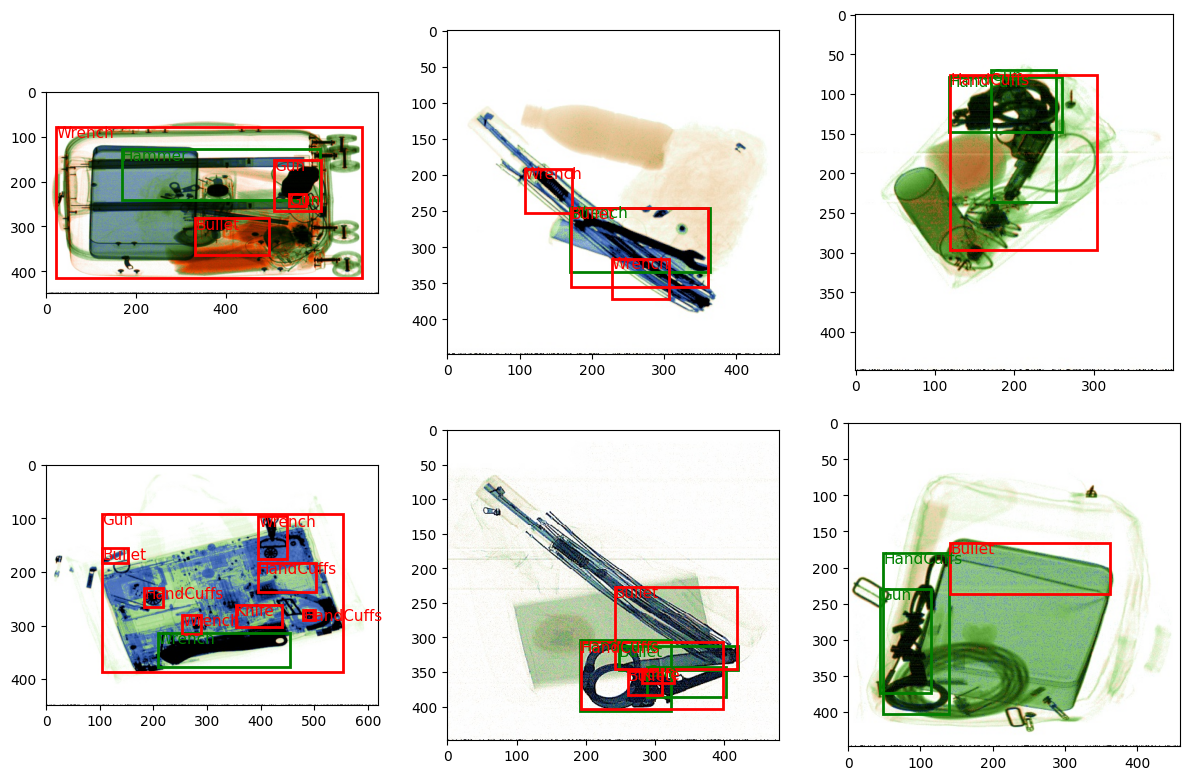

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()
for i, sample in enumerate(tiny_val[:6]):
    img = sample["image"]
    plot_image_with_boxes(
        ax[i],
        sample["image"],
        sample["targets"],
        color="green",
    )
    add_yolo_boxes(ax[i], pred_boxes[i], img.shape, color="red")

plt.tight_layout()

In [16]:
rng = np.random.default_rng(0)

pos = np.where(y_train >= 0)[0]
neg = np.where(y_train == -1)[0]

neg_sub = rng.choice(neg, size=min(len(neg), 10 * len(pos)), replace=False)

idx = np.concatenate([pos, neg_sub])
rng.shuffle(idx)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

clf = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "clf",
            SGDClassifier(
                loss="log_loss",
                class_weight="balanced",
                max_iter=3000,
                tol=1e-3,
                random_state=0,
            ),
        ),
    ]
)

clf.fit(X_train[idx], y_train[idx])

KeyboardInterrupt: 

In [ ]:
y_pred = clf.predict(X_val)

In [ ]:
len(val_boxes)

100

In [ ]:
counts = [len(b) for b in val_boxes]
val_img_ids = np.repeat(np.arange(len(counts)), counts)
val_img_ids

array([ 0,  0,  0, ..., 99, 99, 99], shape=(3364,))

In [ ]:
pred_boxes = []
for i, bboxes in enumerate(val_boxes):
    idx = np.where(val_img_ids == i)[0]
    y_img = y_pred[idx]
    mask = y_img > 0
    y_keep = y_img[mask]
    boxes_keep = bboxes[mask]
    boxes_keep[:, 0] = y_keep
    pred_boxes.append(boxes_keep)


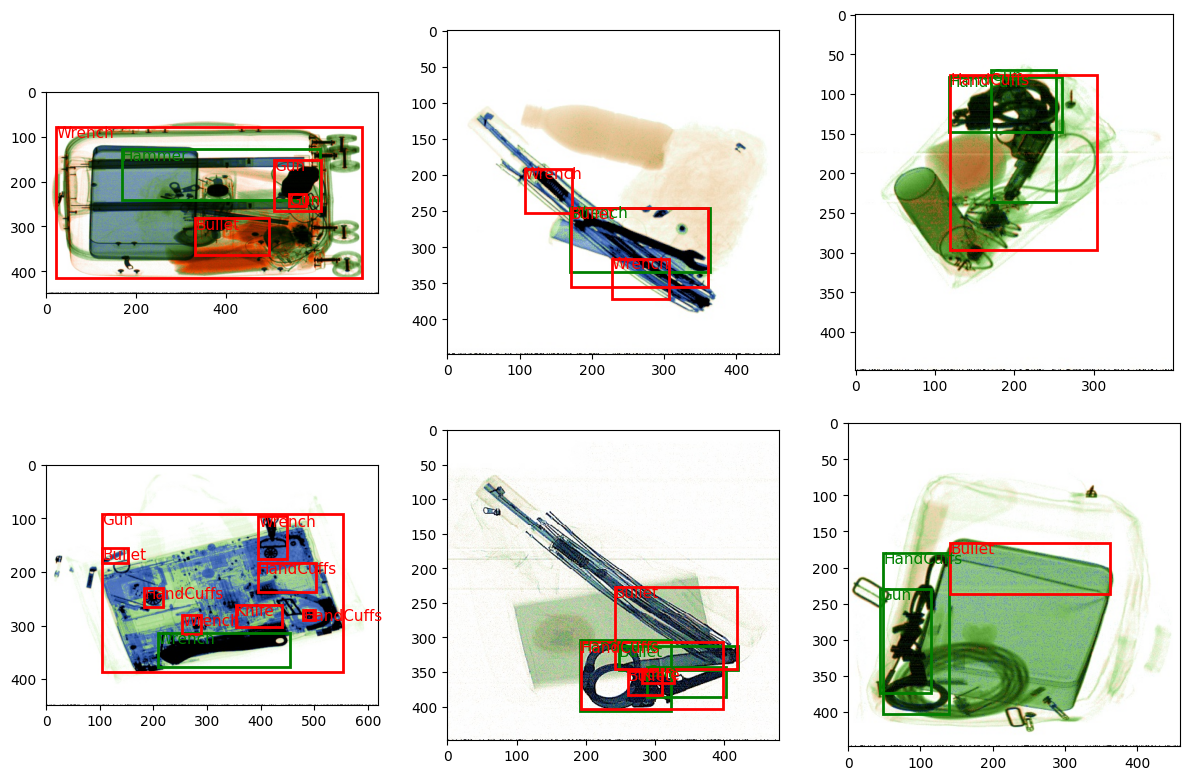

NameError: name 'boxes_img0_true' is not defined

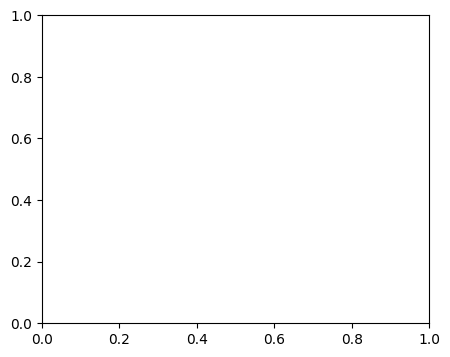

In [ ]:
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot()
plot_image_with_boxes(
    ax,
    img,
    boxes_img0_true,
    color="green",
)
add_yolo_boxes(ax, boxes_img0_pos, img.shape, color="red")

plt.tight_layout()
